In [31]:
import pandas as pd

In [32]:
df= pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\Polynomial Regession\manufacturing-yield.csv')

In [33]:
df.head()

,Batch_ID,Machine_Age_Months,Production_Temperature_C,Pressure_Bar,Machine_Speed_RPM,Raw_Material_Moisture_Pct,Operator_Experience_Years,Batch_Size_KG,Maintenance_Days_Ago,Ambient_Humidity_Pct,Shift,Yield_Rate_Pct
0,B00001,11,153.73,5.01,1456.9,6.01,13.43,268.99,36,29.65,Morning,75.30
1,B00002,93,225.13,6.39,604.5,11.59,5.27,72.80,72,30.19,Morning,71.84
2,B00003,79,254.55,3.13,815.5,2.21,2.38,255.24,54,41.37,Morning,82.80
3,B00004,53,241.21,4.66,1651.7,7.25,18.38,410.18,85,73.66,Morning,87.81
4,B00005,52,180.49,5.20,1250.0,4.75,9.73,316.17,13,48.93,Night,90.00


In [34]:
df.isnull().sum()

Batch_ID                       0
Machine_Age_Months             0
Production_Temperature_C     185
Pressure_Bar                 125
Machine_Speed_RPM              0
Raw_Material_Moisture_Pct    186
Operator_Experience_Years    150
Batch_Size_KG                  0
Maintenance_Days_Ago           0
Ambient_Humidity_Pct         123
Shift                          0
Yield_Rate_Pct                 0
dtype: int64

In [35]:
df['Production_Temperature_C']= df['Production_Temperature_C'].fillna(df['Production_Temperature_C'].median())
df['Pressure_Bar']=df['Pressure_Bar'].fillna(df['Pressure_Bar'].median())
df['Raw_Material_Moisture_Pct']=df['Raw_Material_Moisture_Pct'].fillna(df['Raw_Material_Moisture_Pct'].median())
df['Operator_Experience_Years']= df['Raw_Material_Moisture_Pct'].fillna(df['Raw_Material_Moisture_Pct'].median())
df['Ambient_Humidity_Pct'] = df['Ambient_Humidity_Pct'].fillna(df['Ambient_Humidity_Pct'].median())

In [36]:
df.isnull().sum()

Batch_ID                     0
Machine_Age_Months           0
Production_Temperature_C     0
Pressure_Bar                 0
Machine_Speed_RPM            0
Raw_Material_Moisture_Pct    0
Operator_Experience_Years    0
Batch_Size_KG                0
Maintenance_Days_Ago         0
Ambient_Humidity_Pct         0
Shift                        0
Yield_Rate_Pct               0
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
x= df.drop(columns=['Batch_ID', 'Yield_Rate_Pct'])
y= df['Yield_Rate_Pct']
x = pd.get_dummies(x, drop_first=True, dtype=float)
print(x.shape)
print(y.shape)
print(x.info())


(5000, 11)
(5000,)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Machine_Age_Months         5000 non-null   int64  
 1   Production_Temperature_C   5000 non-null   float64
 2   Pressure_Bar               5000 non-null   float64
 3   Machine_Speed_RPM          5000 non-null   float64
 4   Raw_Material_Moisture_Pct  5000 non-null   float64
 5   Operator_Experience_Years  5000 non-null   float64
 6   Batch_Size_KG              5000 non-null   float64
 7   Maintenance_Days_Ago       5000 non-null   int64  
 8   Ambient_Humidity_Pct       5000 non-null   float64
 9   Shift_Morning              5000 non-null   float64
 10  Shift_Night                5000 non-null   float64
dtypes: float64(9), int64(2)
memory usage: 429.8 KB
None


In [39]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [40]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.fit_transform(x_test)



In [41]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(x_train_poly, y_train)
print('model trainning sucessful !')

model trainning sucessful !


In [42]:
y_pred = model.predict(x_test_poly)

# compare 

result = pd.DataFrame({
    'Actual': [y_test.values],
    'Predicted' : [y_pred]
})

result.head(10)

,Actual,Predicted
0,"[75.83, 77.96, 74.73, 77.49, 75.9, 80.22, 84.0...","[77.5124007942102, 78.3753323651997, 75.753471..."


In [45]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print(f' r2 is : {r2}')


 r2 is : 0.8183176275701431


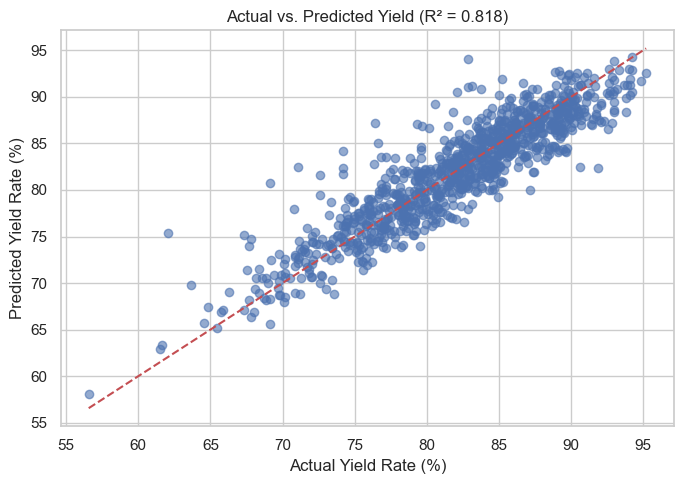

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Yield Rate (%)")
plt.ylabel("Predicted Yield Rate (%)")
plt.title(f"Actual vs. Predicted Yield (R² = {r2:.3f})")
plt.tight_layout()
plt.show()